In [2]:
# 18: 1-8 + 10  + 16

In [6]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ----------- ---------------------------- 2.4/8.4 MB 13.3 MB/s eta 0:00:01
   --------------------------- ------------ 5.8/8.4 MB 14.5 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 14.0 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 13.1 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---- ----------------------------------- 4.5/37.4 MB 21.2 MB/s eta 0:00:02
   -------- ------------------------------- 8.4/37.4 MB 19.8 MB/s eta 0:00:02
   ------------ --------------------------- 11.5/37.4 MB 18.1 MB/s eta 0:00:02
   ---------------- ----------------------- 15.2/37.4 MB 17.6 MB/s eta 0:00:02
   -------------------- ------------------- 18.9/37.4 MB 17.7 MB/s eta 0:00:02
   ------------------------ --------------- 23.1/37.4 MB 17.8 MB/s eta 0:00:01
   ---


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from sklearn import datasets # Wbudowane datasety
from sklearn import preprocessing # Skalowanie, kodowanie
from sklearn import model_selection # Train/test split, CV
from sklearn import metrics # Metryki ewaluacji
from sklearn import linear_model # Modele liniowe
from sklearn import tree # Drzewa decyzyjne
from sklearn import ensemble # Random Forest, Gradient Boosting
from sklearn import neighbors # k-NN
from sklearn import svm # Support Vector Machines
from sklearn import cluster # Klasteryzacja

 Zadanie 1 – Pierwszy model klasyfikacji
Wytrenuj model LogisticRegression na datasecie Iris i oceń jego accuracy.
Dataset: sklearn.datasets.load_iris()
Wymagania:
Podziel dane 80/20 (train/test)



In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris  # Poprawiono import
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

iris = datasets.load_iris()
X, y = iris.data, iris.target
print(X.shape)


# Podział na zbiór treningowy i testowy


X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.2, # 20% na test
random_state=42, # dla reprodukowalności (te same obs zawsze trafiaja do train i test)
stratify=y # zachowanie proporcji klas (w zb treningowym i testowym)
)
print(f"Rozmiar zbioru treningowego: {X_train.shape[0]}")
print(f"Rozmiar zbioru testowego: {X_test.shape[0]}")


# KROK 3: Preprocessing - standaryzacja
# ========================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # fit + transform na train
X_test_scaled = scaler.transform(X_test) # tylko transform na test!
print(f"\nPo standaryzacji:")
print(f" Mean (train): {X_train_scaled.mean():.6f}")

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f" Accuracy: {accuracy:.4f}")


(150, 4)
Rozmiar zbioru treningowego: 120
Rozmiar zbioru testowego: 30

Po standaryzacji:
 Mean (train): -0.000000
 Accuracy: 0.9333


Porównaj accuracy trzech algorytmów na datasecie Wine: LogisticRegression, DecisionTree, KNN.
Dataset: sklearn.datasets.load_wine()
Wymagania:
Ten sam podział train/test dla wszystkich
Wydrukuj wyniki w formie tabeli

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


wine = load_wine()
X, y = wine.data, wine.target

#  Ten sam podział train/test dla wszystkich
#  random_state dla powtarzalności wyników
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


models = {
    "Logistic Regression": LogisticRegression(max_iter=10000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier()
}

#  Trenowanie modeli i zbieranie wyników
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy": acc})

#  Wydruk wyników w formie tabeli
df_results = pd.DataFrame(results)

print("Porównanie dokładności algorytmów na zbiorze Wine:")
print(df_results.to_string(index=False))

Porównanie dokładności algorytmów na zbiorze Wine:
              Model  Accuracy
Logistic Regression  1.000000
      Decision Tree  0.944444
                KNN  0.722222


3. Dla klasyfikacji binarnej na Breast Cancer dataset, stwórz i zwizualizuj confusion matrix.
Dataset: sklearn.datasets.load_breast_cancer()
Wymagania:
Użyj Random Forest
Heatmap confusion matrix z annotacjami
Oblicz precision, recall, F1


--- Wyniki metryk ---
Precision: 0.9589
Recall:    0.9722
F1-Score:  0.9655

--- Raport klasyfikacji ---
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



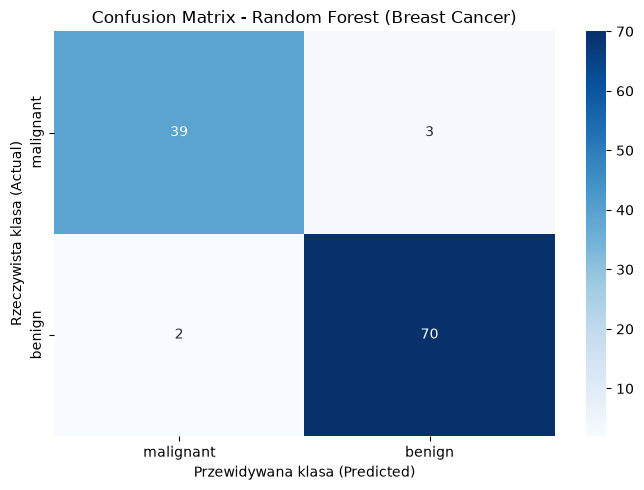

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score


cancer = load_breast_cancer()
X, y = cancer.data, cancer.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)


y_pred = model.predict(X_test)


precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("--- Wyniki metryk ---")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}\n")


print("--- Raport klasyfikacji ---")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.title('Confusion Matrix - Random Forest (Breast Cancer)')
plt.xlabel('Przewidywana klasa (Predicted)')
plt.ylabel('Rzeczywista klasa (Actual)')
plt.tight_layout()
plt.show()

Przeprowadź regresję liniową na California Housing i oceń R².
Dataset: sklearn.datasets.fetch_california_housing()
Wymagania:
Standaryzacja cech
Oblicz RMSE i R²
Scatter plot: predicted vs actual


--- Wyniki ewaluacji modelu ---
RMSE (Root Mean Squared Error): 0.7456
R² (Współczynnik determinacji):  0.5758



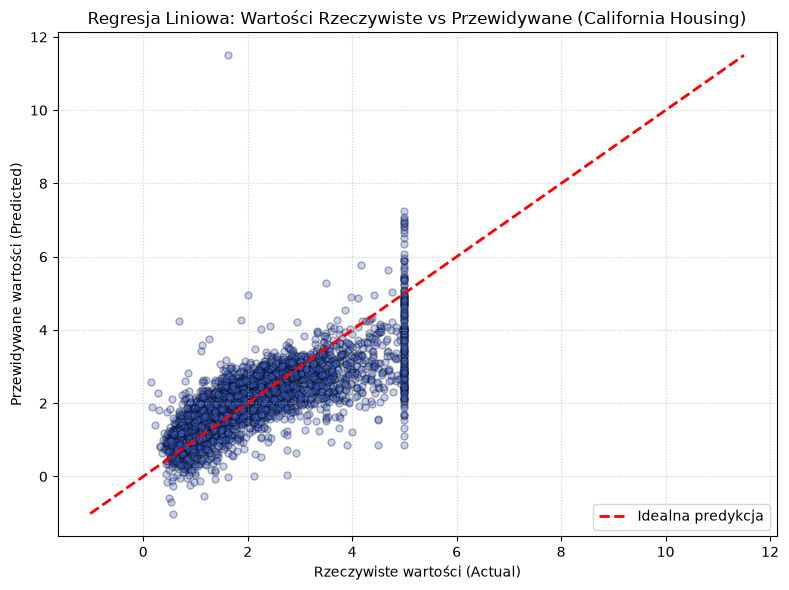

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


housing = fetch_california_housing()
X, y = housing.data, housing.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standaryzacja cech (Scaler dopasowany tylko na zbiorze treningowym)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = LinearRegression()
model.fit(X_train_scaled, y_train)


y_pred = model.predict(X_test_scaled)

# RMSE oraz R²
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Wyniki ewaluacji modelu ---")
print(f"RMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"R² (Współczynnik determinacji):  {r2:.4f}\n")

#  Scatter plot: predicted vs actual (Przewidywane vs Rzeczywiste)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='royalblue', edgecolor='k', s=25)

# Linia idealnej predykcji (y = x)
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Idealna predykcja')

plt.title('Regresja Liniowa: Wartości Rzeczywiste vs Przewidywane (California Housing)')
plt.xlabel('Rzeczywiste wartości (Actual)')
plt.ylabel('Przewidywane wartości (Predicted)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Przeprowadź klasteryzację K-Means na syntetycznych danych.
Dane: sklearn.datasets.make_blobs(n_samples=300, centers=3)
Wymagania:
Użyj metody łokcia do wyboru k
Zwizualizuj klastry z centroidami


[19884.398329041524]
[19884.398329041524, 5335.122314158597]
[19884.398329041524, 5335.122314158597, 204.0694384047887]
[19884.398329041524, 5335.122314158597, 204.0694384047887, 179.33291317971714]
[19884.398329041524, 5335.122314158597, 204.0694384047887, 179.33291317971714, 153.74695328151267]
[19884.398329041524, 5335.122314158597, 204.0694384047887, 179.33291317971714, 153.74695328151267, 131.39885751526347]
[19884.398329041524, 5335.122314158597, 204.0694384047887, 179.33291317971714, 153.74695328151267, 131.39885751526347, 110.97789763816479]
[19884.398329041524, 5335.122314158597, 204.0694384047887, 179.33291317971714, 153.74695328151267, 131.39885751526347, 110.97789763816479, 97.23083183136868]
[19884.398329041524, 5335.122314158597, 204.0694384047887, 179.33291317971714, 153.74695328151267, 131.39885751526347, 110.97789763816479, 97.23083183136868, 84.36747906985968]
[19884.398329041524, 5335.122314158597, 204.0694384047887, 179.33291317971714, 153.74695328151267, 131.398857

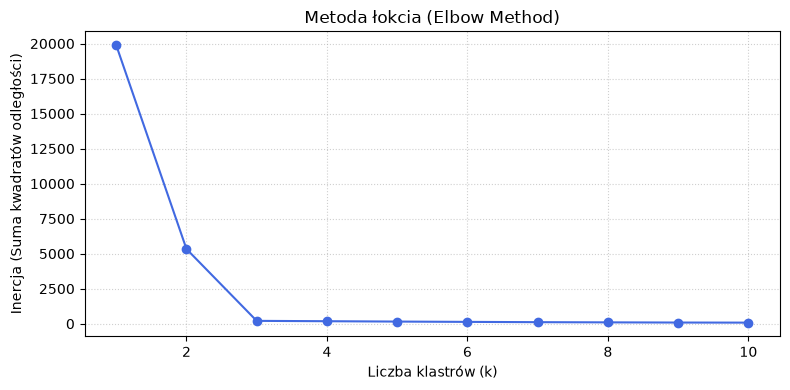

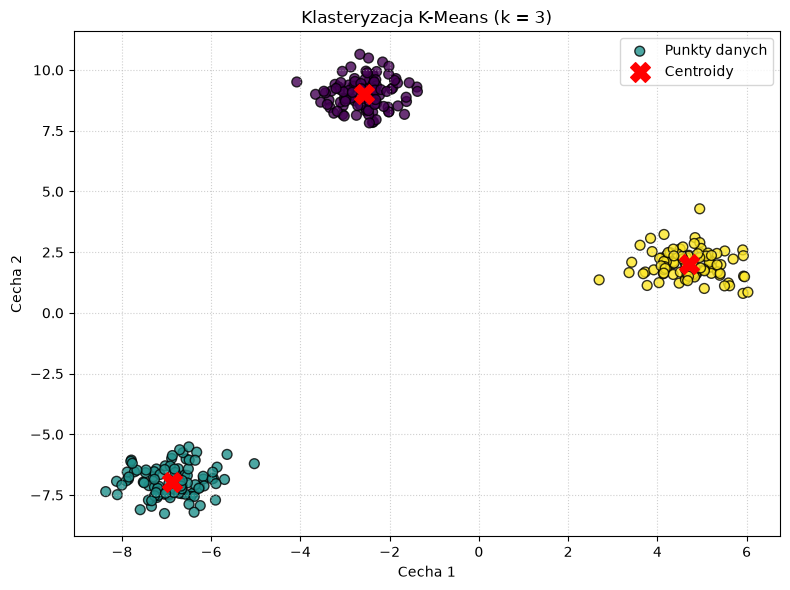

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans


X, y_true = make_blobs(n_samples=300, centers=3, cluster_std=0.60, random_state=42)

# 2. Metoda łokcia do wyboru optymalnej liczby k
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)
    # print(inertia)

# Wykres metody łokcia
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='royalblue')
plt.title('Metoda łokcia (Elbow Method)')
plt.xlabel('Liczba klastrów (k)')
plt.ylabel('Inercja (Suma kwadratów odległości)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_


plt.figure(figsize=(8, 6))

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis', alpha=0.8, edgecolor='k', label='Punkty danych')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Centroidy')

plt.title(f'Klasteryzacja K-Means (k = {optimal_k})')
plt.xlabel('Cecha 1')
plt.ylabel('Cecha 2')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Przeprowadź PCA na datasecie Digits i zwizualizuj w 2D.
Dataset: sklearn.datasets.load_digits()
Wymagania:
Redukcja do 2 komponentów
Scatter plot z kolorowaniem według cyfry
Ile % wariancji wyjaśnia 2 komponenty?

--- Wyniki PCA ---
Wariancja wyjaśniona przez 1. komponent: 14.89%
Wariancja wyjaśniona przez 2. komponent: 13.62%
Łącznie 2 komponenty wyjaśniają:        28.51%



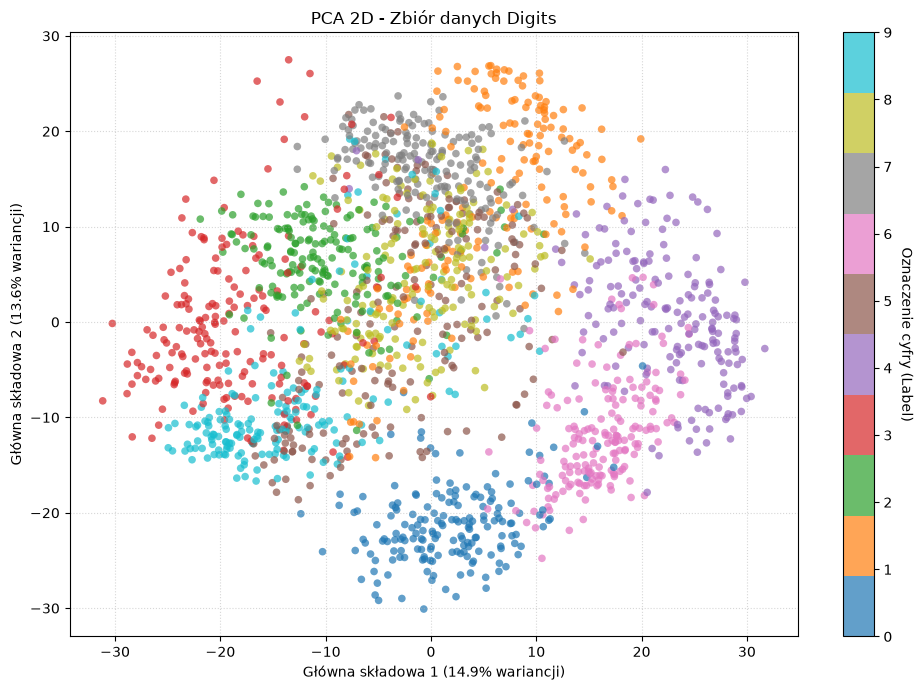

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA


digits = load_digits()
X, y = digits.data, digits.target


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)


explained_variance_ratio = pca.explained_variance_ratio_
total_explained_variance = sum(explained_variance_ratio) * 100

print("--- Wyniki PCA ---")
print(f"Wariancja wyjaśniona przez 1. komponent: {explained_variance_ratio[0]*100:.2f}%")
print(f"Wariancja wyjaśniona przez 2. komponent: {explained_variance_ratio[1]*100:.2f}%")
print(f"Łącznie 2 komponenty wyjaśniają:        {total_explained_variance:.2f}%\n")


plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca[:, 0], 
    X_pca[:, 1], 
    c=y, 
    cmap='tab10', 
    alpha=0.7, 
    edgecolor='none', 
    s=30
)


cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label('Oznaczenie cyfry (Label)', rotation=270, labelpad=15)

plt.title('PCA 2D - Zbiór danych Digits')
plt.xlabel(f'Główna składowa 1 ({explained_variance_ratio[0]*100:.1f}% wariancji)')
plt.ylabel(f'Główna składowa 2 ({explained_variance_ratio[1]*100:.1f}% wariancji)')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

7. Przeprowadź 5-fold cross-validation dla Random Forest na Iris.
Wymagania:
Użyj StratifiedKFold
Wydrukuj mean i std accuracy
Boxplot scores per fold


--- Wyniki 5-Fold Cross-Validation (Accuracy) ---
Fold 1: 0.9667
Fold 2: 0.9667
Fold 3: 0.9333
Fold 4: 0.9667
Fold 5: 0.9000

--------------------------------------------------
Średnia Accuracy (Mean):     0.9467
Odchylenie standardowe (Std): 0.0267
--------------------------------------------------



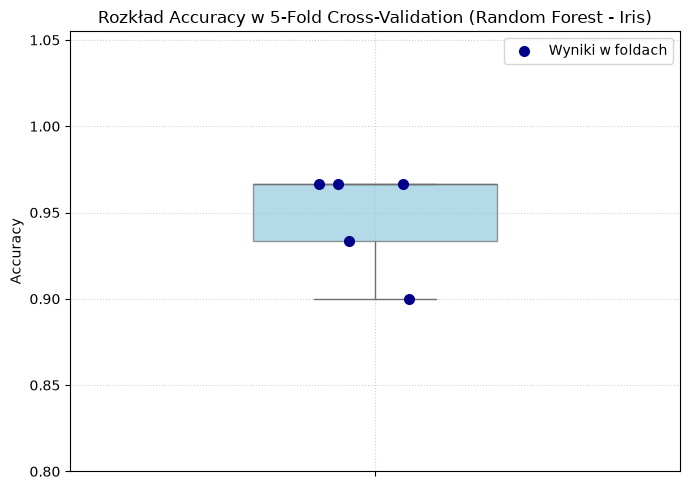

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

iris = load_iris()
X, y = iris.data, iris.target

model = RandomForestClassifier(random_state=42)


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#  walidacja krzyżowa i obliczenie accuracy dla każdego folda
scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')

# Wydruk średniej (mean) oraz odchylenia standardowego (std)
mean_acc = np.mean(scores)
std_acc = np.std(scores)

print("--- Wyniki 5-Fold Cross-Validation (Accuracy) ---")
for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.4f}")

print("\n--------------------------------------------------")
print(f"Średnia Accuracy (Mean):     {mean_acc:.4f}")
print(f"Odchylenie standardowe (Std): {std_acc:.4f}")
print("--------------------------------------------------\n")

#  Boxplot z zaznaczonymi wynikami poszczególnych foldów
plt.figure(figsize=(7, 5))
sns.boxplot(y=scores, color='skyblue', width=0.4, boxprops=dict(alpha=0.7))
sns.stripplot(y=scores, color='darkblue', size=8, jitter=True, label='Wyniki w foldach')

plt.title('Rozkład Accuracy w 5-Fold Cross-Validation (Random Forest - Iris)')
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.055)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

8. Dla Random Forest na Wine dataset, zwizualizuj feature importance.
Dataset: sklearn.datasets.load_wine()
Wymagania:
Horizontal bar plot
Sortowanie od najważniejszej
Dodaj wartości na słupkach

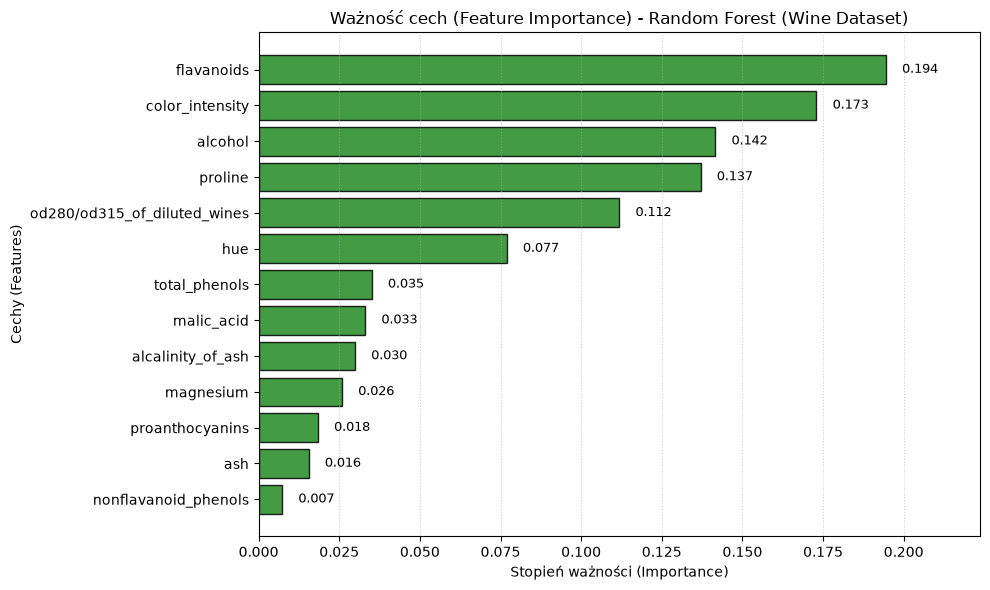

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier

wine = load_wine()
X, y = wine.data, wine.target
feature_names = wine.feature_names

model = RandomForestClassifier(random_state=42)
model.fit(X, y)

# Pobranie ważności cech (feature importances)
importances = model.feature_importances_

#  Przygotowanie ramki danych i sortowanie rosnąco -po odwróceniu osi na wykresie najwazniejsza cecha będzie na samej górze
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

#  Poziomy wykres słupkowy (Horizontal bar plot)
plt.figure(figsize=(10, 6))
bars = plt.barh(
    df_importance['Feature'], 
    df_importance['Importance'], 
    color='forestgreen', 
    alpha=0.85, 
    edgecolor='k'
)

# Dodanie wartości liczbowych bezpośrednio na słupkach
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.005,                        # Pozycja X (tuż obok końca słupka)
        bar.get_y() + bar.get_height() / 2,   # Pozycja Y (środek słupka)
        f'{width:.3f}',                       # Wartość zformatowana do 3 miejsc po przecinku
        va='center', 
        ha='left', 
        fontsize=9, 
        color='black'
    )

plt.title('Ważność cech (Feature Importance) - Random Forest (Wine Dataset)')
plt.xlabel('Stopień ważności (Importance)')
plt.ylabel('Cechy (Features)')
plt.xlim(0, df_importance['Importance'].max() * 1.15)  # Margines po prawej stronie na etykiety tekstowe
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
 Zadanie 10 Analiza ROC-AUC
Porównaj 3 modele klasyfikacji binarnej za pomocą ROC curves.
Dataset: Breast Cancer
Wymagania:
Logistic Regression, Random Forest, SVM
Wykres ROC curves na jednym wykresie
Wydrukuj AUC dla każdego modelu


AUC dla Logistic Regression: 0.9954
AUC dla Random Forest: 0.9937


C:\Users\czeralpl\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


AUC dla SVM: 0.9950


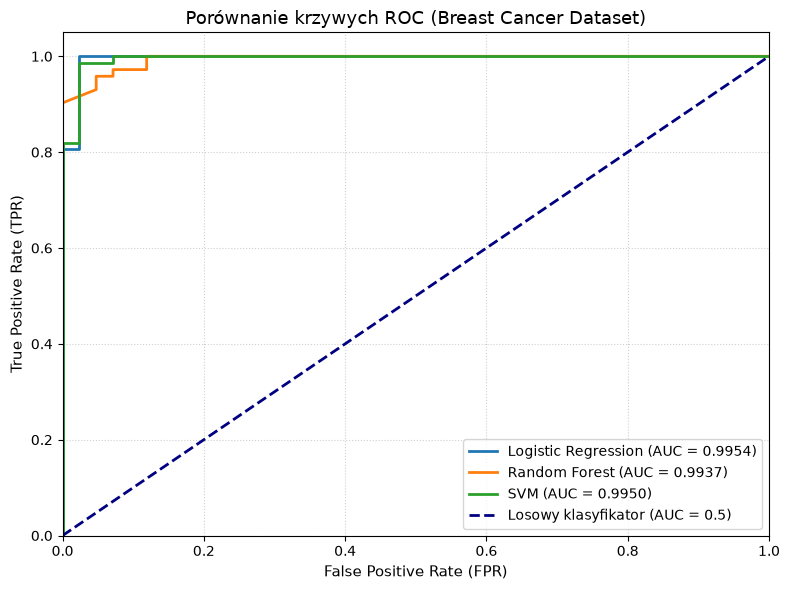

In [36]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc


data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# pipeline ze StandardScaler dla modeli wrażliwych na skalę (LogReg, SVM)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))
}

# . Trening modeli, predykcja prawdopodobieństw i obliczenie ROC-AUC
plt.figure(figsize=(8, 6))

for name, model in models.items():
    model.fit(X_train, y_train)
    
    # Pobieramy prawdopodobieństwa dla klasy pozytywnej (klasa 1)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # Obliczenie False Positive Rate, True Positive Rate oraz progu
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    
    # Obliczenie pola pod krzywą (AUC)
    roc_auc = auc(fpr, tpr)
    
    # Wydruk AUC dla każdego modelu
    print(f"AUC dla {name}: {roc_auc:.4f}")
    
    # Rysowanie krzywej ROC na wspólnym wykresie
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.4f})')

# 
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Losowy klasyfikator (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.title('Porównanie krzywych ROC (Breast Cancer Dataset)', fontsize=13)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
Zadanie 16 – Analiza wrażliwości na hiperparametry
Zbadaj wpływ hiperparametrów na performance Random Forest.
Dataset: Wine
Wymagania:
Zbadaj: n_estimators (10, 50, 100, 200), max_depth (3, 5, 10, None)
Heatmap: n_estimators vs max_depth (accuracy)
Czas treningu dla każdej kombinacji
Rekomendacja: optymalne hiperparametry


--- Wyniki analizy wrażliwości hiperparametrów ---
 n_estimators max_depth  accuracy     time
           10         3  0.944444 0.097641
           10         5  0.955397 0.066243
           10        10  0.949683 0.066358
           10      None  0.949683 0.064877
           50         3  0.972222 0.296863
           50         5  0.966508 0.282423
           50        10  0.960952 0.303058
           50      None  0.960952 0.273662
          100         3  0.972222 0.613350
          100         5  0.972063 0.617813
          100        10  0.972063 0.598394
          100      None  0.972063 0.601876
          200         3  0.983333 1.140251
          200         5  0.966508 1.131815
          200        10  0.966508 1.171650
          200      None  0.966508 1.164666

--------------------------------------------------
 rekomendacja - Optymalne hiperparametry:
 • n_estimators: 200
 • max_depth:    3
 • Accuracy:     0.9833
--------------------------------------------------



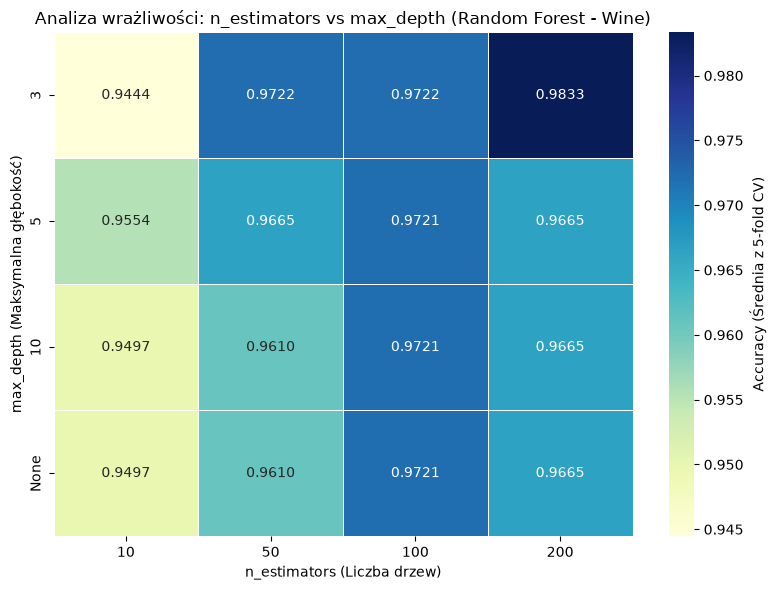

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier


wine = load_wine()
X, y = wine.data, wine.target

# definicja hiperparametrów do sprawdzenia
n_estimators_list = [10, 50, 100, 200]
max_depth_list = [3, 5, 10, None]

results = []

# kombinacje hiperparametrów z pomiarem czasu i walidacją krzyżową (5-fold)
for n_est in n_estimators_list:
    for depth in max_depth_list:
        model = RandomForestClassifier(
            n_estimators=n_est, 
            max_depth=depth, 
            random_state=42
        )
        
        # Pomiar czasu wykonania 5-krotnej walidacji krzyżowej
        start_time = time.time()
        scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
        end_time = time.time()
        
        train_time = end_time - start_time
        mean_acc = np.mean(scores)
        
        # Zamiana wartości None na string na potrzeby czytelnej tabeli i wykresu
        depth_label = str(depth) if depth is not None else "None"
        
        results.append({
            'n_estimators': n_est,
            'max_depth': depth_label,
            'accuracy': mean_acc,
            'time': train_time
        })

df_results = pd.DataFrame(results)

print("--- Wyniki analizy wrażliwości hiperparametrów ---")
print(df_results.to_string(index=False))

#  Znalezienie optymalnych hiperparametrów
best_idx = df_results['accuracy'].idxmax()
best_config = df_results.loc[best_idx]

print("\n--------------------------------------------------")
print(" rekomendacja - Optymalne hiperparametry:")
print(f" • n_estimators: {best_config['n_estimators']}")
print(f" • max_depth:    {best_config['max_depth']}")
print(f" • Accuracy:     {best_config['accuracy']:.4f}")
print("--------------------------------------------------\n")

# Przygotowanie danych pod Heatmapę 
# Ustawienie odpowiedniej kolejności wierszy dla max_depth
depth_order = ['3', '5', '10', 'None']
pivot_accuracy = df_results.pivot(index='max_depth', columns='n_estimators', values='accuracy')
pivot_accuracy = pivot_accuracy.reindex(depth_order)

# Heatmapa n_estimators vs max_depth (Accuracy)
plt.figure(figsize=(8, 6))
sns.heatmap(
    pivot_accuracy, 
    annot=True, 
    fmt='.4f', 
    cmap='YlGnBu', 
    cbar_kws={'label': 'Accuracy (Średnia z 5-fold CV)'},
    linewidths=0.5,
    edgecolor='gray'
)

plt.title('Analiza wrażliwości: n_estimators vs max_depth (Random Forest - Wine)')
plt.xlabel('n_estimators (Liczba drzew)')
plt.ylabel('max_depth (Maksymalna głębokość)')
plt.tight_layout()
plt.show()